# VaR of Equity Portfolio

This problem uses weekly return data from data/spx_returns_weekly.xlsx.

In [183]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

returns_df = pd.read_excel("spx_returns_weekly.xlsx", sheet_name ="spx returns")
returns_df = returns_df.set_index("date")
returns_df.head()

,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
date,,,,,,,,,,,,,,,,,,,,,
2015-07-10,-0.004549,-0.024991,0.014953,NaN,0.010525,0.014916,0.014898,-0.001981,-0.044579,-0.029600,...,-0.017277,0.003477,0.022240,-0.011065,-0.036483,NaN,-0.007537,-0.012755,-0.023837,-0.027945
2015-07-17,0.013958,0.051426,0.018481,NaN,0.004226,-0.001441,0.017209,0.018737,0.015444,0.017157,...,-0.025888,-0.021078,0.004474,0.004744,0.011868,NaN,-0.028467,0.006460,0.040364,0.017888
2015-07-24,-0.016019,-0.039501,-0.027289,NaN,0.023046,0.013994,0.006868,-0.013642,-0.063560,-0.017283,...,-0.023294,0.007080,-0.024926,-0.032320,-0.032951,NaN,-0.013313,-0.007814,-0.028814,0.035356
2015-07-31,0.041719,-0.025701,0.028349,NaN,-0.007053,0.015512,0.019175,0.012472,-0.002736,0.004872,...,0.030904,0.007810,0.055082,-0.009132,-0.002888,NaN,0.012110,-0.024284,-0.029399,-0.010305
2015-08-07,-0.023443,-0.043341,-0.019855,NaN,-0.011440,0.010650,0.006110,0.008538,0.021945,-0.021089,...,0.012058,0.004114,0.016728,-0.030048,-0.029829,NaN,-0.001710,-0.022485,-0.014401,-0.013679


# 1 Diversification

1.1 Using the full sample, calculate for each series the (unconditional)

- volatility

- empirical VaR (.05)

- empirical CVaR (.05)

Recall that by empirical we refer to the direct quantile estimation. (For example, using .quantile() in pandas.

In [184]:
sample_vol = returns_df.std() * np.sqrt(52)         #annualized

sample_VaR = returns_df.quantile(0.05)

sample_CVaR = returns_df[returns_df <= sample_VaR].mean()

emp_metrics_df = pd.DataFrame({"Volatility": sample_vol, "VaR": sample_VaR, "CVaR": sample_CVaR})
emp_metrics_df

,Volatility,VaR,CVaR
A,0.262258,-0.057326,-0.076165
AAPL,0.277602,-0.054889,-0.082999
ABBV,0.275691,-0.060787,-0.084019
ABNB,0.440293,-0.102721,-0.121221
ABT,0.234069,-0.054879,-0.072602
...,...,...,...
XYZ,0.582606,-0.123189,-0.171470
YUM,0.238865,-0.043275,-0.071547
ZBH,0.275844,-0.059840,-0.091857
ZBRA,0.397162,-0.086037,-0.122058


In [185]:
avg_VaR = emp_metrics_df["VaR"].mean()

median_VaR = emp_metrics_df["VaR"].median()

avg_CVaR = emp_metrics_df["CVaR"].mean()

median_CVaR = emp_metrics_df["CVaR"].median()

max_VaR = emp_metrics_df["VaR"].max()

max_CVaR = emp_metrics_df["CVaR"].max()

print("Average VaR: ", f"{avg_VaR:.3f}")
print("Median VaR: ", f"{median_VaR:.3f}")
print("Average CVaR: ", f"{avg_CVaR:.3f}")
print("Median CVaR: ", f"{median_CVaR:.3f}")
print("Max VaR: ", f"{max_VaR:.3f}")
print("Max CVaR: ", f"{max_CVaR:.3f}")

Average VaR:  -0.065
Median VaR:  -0.061
Average CVaR:  -0.097
Median CVaR:  -0.091
Max VaR:  -0.032
Max CVaR:  -0.051


# 1.2 Form an equally-weighted portfolio of the investments.

Calculate the statistics of 1.1 for this portfolio, and compare the results to the individual return statistics. What do you find? What is driving this result?

In [186]:
returns_port = returns_df.mean(axis=1)
#calc return metrics
port_vol = returns_port.std() * np.sqrt(52)         #annualized

port_VaR = returns_port.quantile(0.05)

port_CVaR = returns_port[returns_port <= port_VaR].mean()

print("Volatility: ", f"{port_vol:.3f}")
print("VaR: ", f"{port_VaR:.3f}")
print("CVaR: ", f"{port_CVaR:.3f}")


Volatility:  0.183
VaR:  -0.034
CVaR:  -0.059


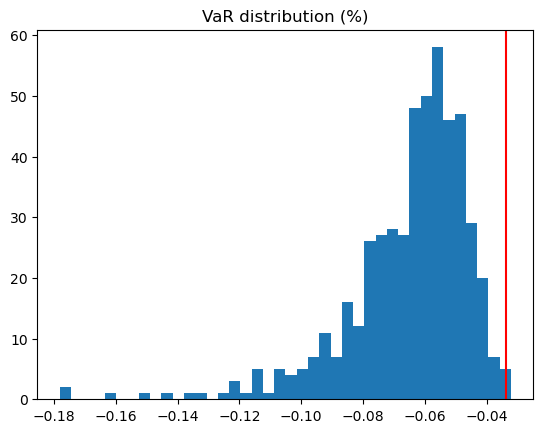

In [187]:
plt.hist(sample_VaR, bins=40)
plt.title("VaR distribution (%)")
plt.axvline(port_VaR, color="red", label="EW portfolio") 
plt.show()

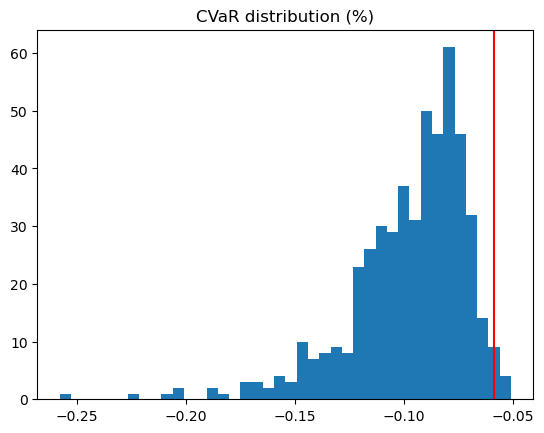

In [188]:
plt.hist(sample_CVaR, bins=40)
plt.title("CVaR distribution (%)")
plt.axvline(port_CVaR, color="red", label="EW portfolio") 
plt.show()

_Answer:_ As seen in the figures above, the diversified, equally weighted portfolio has among the best tail-risk metrics, with a VaR of only -0.034 and a CVaR of only -0.059 (vs. averages across individual stocks of -0.065 and -0.097, respectively). Indeed, only one individual stock (RSG, at -0.032) had a higher (less negative) VaR than the equally weighted portfolio.

The driver of the result is diversification. VaR and CVaR measure the tail risk of the asset, that is, the return threshold of the worst 5% of weeks (VaR) and the average return within those weeks (CVaR). Although it is true that the stocks in the S&P 500 are highly correlated, and a bad week for one is often a bad week for the others, what happens when you have 500 stocks is that large falls in individual stocks are offset by the other stocks in the portfolio, preventing large falls and making them unusual. 

However, this does not mean that the risk goes to zero. Diversification removes idiosyncratic risk but not market risk, which is what remains after constructing the portfolio.

# 1.3 

Re-calculate 1.2, but this time drop your most volatile asset, and replace the portion it was getting with 0. (You could imagine we’re replacing the most volatile asset with a negligibly small risk-free rate.)

In comparing the answer here to 1.2, how much risk is your most volatile asset adding to the portfolio? Is this in line with the amount of risk we measured in the stand-alone risk-assessment of 1.1?

In [189]:
#drop most vol asset

max_vol_stock = emp_metrics_df["Volatility"].idxmax()
adj_returns = returns_df.drop(max_vol_stock, axis=1)
adj_returns["risk-free"] = 0

#calculate returns
adj_returns_port = adj_returns.mean(axis=1)

#calc return metrics
adj_port_vol = adj_returns_port.std() * np.sqrt(52)         #annualized

adj_port_VaR = adj_returns_port.quantile(0.05)

adj_port_CVaR = adj_returns_port[adj_returns_port <= adj_port_VaR].mean()

print("Volatility: ", f"{adj_port_vol:.3f}")
print("VaR: ", f"{adj_port_VaR:.3f}")
print("CVaR: ", f"{adj_port_CVaR:.3f}")

Volatility:  0.183
VaR:  -0.034
CVaR:  -0.059


_Answer:_ Compared to the portfolio in 1.2, the most volatile asset is adding practically no downside risk, as both the VaR and the CVaR stay at the same level when we drop it and replace it with the risk-free rate (-0.034 and -0.059, respectively). This goes back to the point about diversification, and how after a certain threshold we have eliminated idiosyncratic risk almost entirely, and therefore there is no difference between a portfolio with 503 stocks and one with 502 stocks.

Compared to the stand-alone risk assessment in part 1.1, we get to the same conclusion as in part 1.2: idiosyncratic risk is almost entirely diversified away and what is left is only the market risk, which is less than almost all of the individual tail risks.

# 2. Dynamic Measures

## 2.1

Let's measure the **conditional** statistics of the equally-weighted portfolio of `1.2`, as of the end of the sample.



### Volatility

For each security, calculate the **rolling** volatility series, $\sigma_t$, with a window of $m = 26$.

The value at $\sigma_t$ in the notes denotes the estimate using data through time $t-1$, and thus (potentially) predicting the volatility at $\sigma_t$.



In [190]:
m = 26
vol = []

for t in range(m, len(returns_port)):
    rol_vol = returns_port[t-m:t].std() 
    vol.append(rol_vol)


### Mean

Suppose we can approximate that the weekly mean return is zero.


### VaR

Calculate the **normal VaR** and **normal CVaR** for $q = .05$ and $\tau = 1$ as of the end of the sample. Use the approximation, $\mathbf{z}_{.05} = -1.65$.

In [191]:
normal_VaR = []
normal_CVaR = []

for i in vol:
    VaR = -1.65*i # mean zero
    normal_VaR.append(VaR)

for i in vol:
    CVaR_t = -(norm.pdf(-1.65) / 0.05) * i    # average of bottom 5% 
    normal_CVaR.append(CVaR_t)


# Conclude and Compare


- volatility (annualized).

- normal VaR (.05)

- normal CVaR (.05)

How do these compare to the answers in 1.2?

In [192]:
results = pd.Series({
    "Vol (ann.)":   vol[-1] * np.sqrt(52),
    "Normal VaR":   normal_VaR[-1],
    "Normal CVaR":  normal_CVaR[-1],
})

results

Vol (ann.)     0.114222
Normal VaR    -0.026136
Normal CVaR   -0.032397
dtype: float64

_Answer:_ In part 1.2, we had an annualized volatility of 0.183, a VaR of -0.034, and a CVaR of -0.059. Our dynamic measures give a lower expected volatility (0.114 vs. 0.183), a lower VaR (-0.026 vs. -0.034), and a significantly lower CVaR (-0.032 vs. -0.059). The latter is due to the normality assumption, which makes the tails of the distribution "skinnier" than what we see empirically. This would seem to suggest that the normality assumption potentially understates the true tail risk.

Furthermore, using a 26-week rolling window may not be quick enough in identifying a regime switch, and therefore may underestimate the risk of a sudden, significant drop in the portfolio value.

## 2.2

Backtest the VaR using the **hit test**. Namely, check how many times the realized return at $t$ was smaller than the VaR return calculated using $\sigma_t$, (where again remember the notation in the notes uses $\sigma_t$ as a vol based on data through $t-1$.)

Report the percentage of "hits" using both the

- expanding volatility


In [193]:
# expanding vol
exp_vol = []

for t in range(m, len(returns_port)):
    sigma = returns_port.iloc[:t].std()     
    exp_vol.append(sigma)

# expanding vol VaR
exp_VaR = []
for s in exp_vol:
    VaR = -1.65 * s                         
    exp_VaR.append(VaR)

# hit test
df = returns_port.to_frame(name="port_ret")
df = df[-len(exp_VaR):]
df["VaR Estimate"] = exp_VaR

exp_hits = 0
for i in range(len(df)):
    if df["port_ret"].iloc[i] <= df["VaR Estimate"].iloc[i]:
        exp_hits += 1

exp_hit_rate = exp_hits / len(df)
exp_hit_rate

0.038391224862888484

- rolling volatility

In [194]:
df = returns_port.to_frame(name="port_ret")
df = df[-len(normal_VaR):]
df["VaR Estimate"] = normal_VaR

rol_hits = 0
for i in range(len(df)):
    if df["port_ret"].iloc[i] <= df["VaR Estimate"].iloc[i]:
        rol_hits += 1
    
rol_hit_rate = rol_hits / len(df)
rol_hit_rate

0.04936014625228519

_Answer:_ As seen from the results above, the rolling volatility is a better method than the expanding volatility, as it has a hit rate closer to 5% (4.94% vs. 3.84%). This indicates that the expanding volatility method is overly conservative, as it gives a VaR threshold that is more severe than the realized 5th percentile. This is probably because the expanding volatility method incorporates many different market regimes (including those with high vol), whereas the rolling volatility method incorporates only the most recent months and therefore adapts to the current level of volatility.